# Notebook 02 — Pré-processamento e outliers

Corta as bordas, converte em absorbância, suaviza (Savitzky-Golay), calcula a 1ª derivada e o SNV,
detecta outliers (z-score, T² e Q) e salva os espectros tratados sem os outliers.

**Entradas:** `dados_brutos.npz`, `df_limpo.pkl` · **Saídas:** `espectros_pp.npz`, `df_pp.pkl`, figuras `02_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)
from sklearn.decomposition import PCA

## 1. Tratamentos espectrais

In [2]:
d = np.load(cfg.PASTA / 'dados_brutos.npz')
X, y, wl_orig = d['X'], d['y'], d['wl_orig']
df = pd.read_pickle(cfg.PASTA / 'df_limpo.pkl')
cols_esp, cols_ref = utils.identificar_colunas(df, cfg.PREFIXO)

wl, X_corte = utils.corta(X, wl_orig)
print(f'Bandas: {len(wl_orig)} -> {len(wl)} ({wl.min():.0f} a {wl.max():.0f} nm)')

_, X_abs = utils.preprocessa(X, wl_orig, 'abs')
_, X_suav = utils.preprocessa(X, wl_orig, 'sg')
_, X_d1 = utils.preprocessa(X, wl_orig, 'd1')
_, X_snv = utils.preprocessa(X, wl_orig, 'snv')

Bandas: 2151 -> 2001 (450 a 2450 nm)


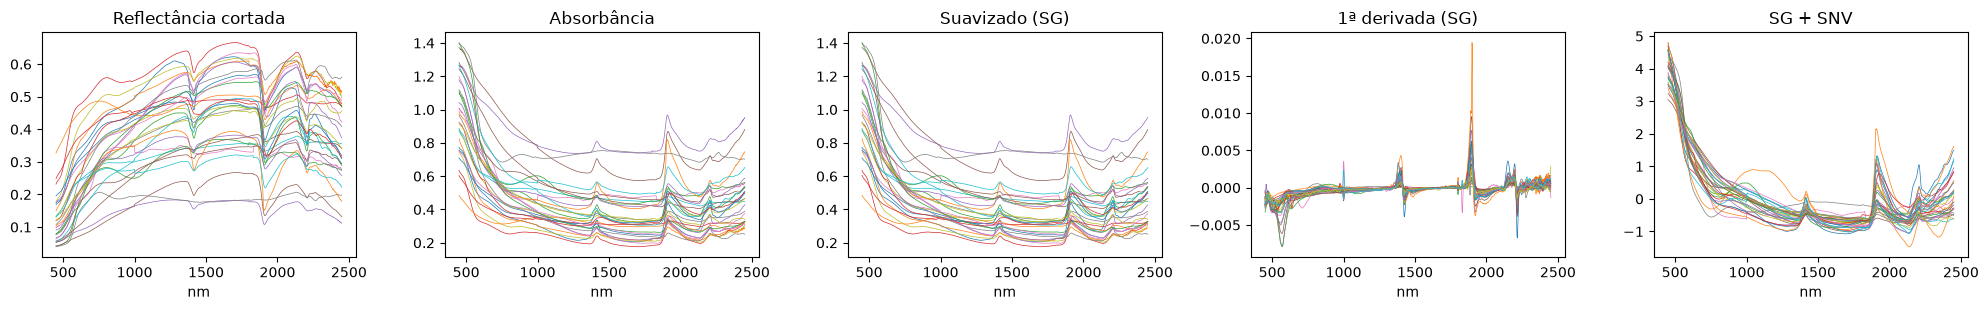

In [3]:
etapas = [(X_corte, 'Reflectância cortada'), (X_abs, 'Absorbância'), (X_suav, 'Suavizado (SG)'),
          (X_d1, '1ª derivada (SG)'), (X_snv, 'SG + SNV')]
amostra = np.random.default_rng(cfg.SEED).choice(len(X), 30, replace=False)   # 30 espectros sorteados
fig, ax = plt.subplots(1, 5, figsize=(20, 3.2))
for a, (M, titulo) in zip(ax, etapas):
    a.plot(wl, M[amostra].T, lw=0.5)
    a.set_title(titulo); a.set_xlabel('nm')
plt.tight_layout(); utils.salva_figura(fig, '02_etapas_preprocessamento.png'); plt.show()

## 2. SNV e detecção de outliers

Três critérios complementares:

- **z-score** do espectro médio, calculado na absorbância suavizada (antes do SNV, que zera a média);
- **T² de Hotelling**: distância ao centro da nuvem nos primeiros PCs;
- **Q**: resíduo de reconstrução, a parte do espectro que os PCs não reproduzem.

Uma amostra é sinalizada se ultrapassar qualquer um dos limites.

In [4]:
m = X_suav.mean(axis=1)
z = np.abs((m - m.mean()) / m.std())

pca_out = PCA(n_components=cfg.N_PCS_OUTLIER).fit(X_snv)
t2, q = utils.t2_q(pca_out, X_snv)
lt2, lq = np.percentile(t2, cfg.PERC_OUTLIER), np.percentile(q, cfg.PERC_OUTLIER)

out = (z > cfg.Z_OUTLIER) | (t2 > lt2) | (q > lq)
idx_out = np.where(out)[0]
print(f'Sinalizadas pelo z-score: {(z > cfg.Z_OUTLIER).sum()}')
print(f'Sinalizadas pelo T²: {(t2 > lt2).sum()}')
print(f'Sinalizadas pelo Q: {(q > lq).sum()}')
print(f'Total sinalizado (qualquer critério): {out.sum()}')

Sinalizadas pelo z-score: 5
Sinalizadas pelo T²: 12
Sinalizadas pelo Q: 12
Total sinalizado (qualquer critério): 25


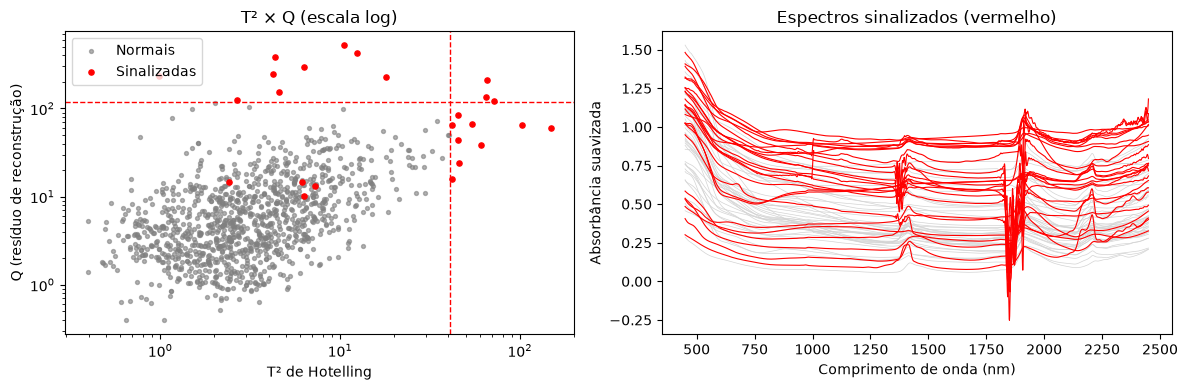

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(t2[~out], q[~out], s=8, c='gray', alpha=0.6, label='Normais')
ax[0].scatter(t2[out], q[out], s=14, c='red', label='Sinalizadas')
ax[0].axvline(lt2, color='red', ls='--', lw=1); ax[0].axhline(lq, color='red', ls='--', lw=1)
ax[0].set_xlabel('T² de Hotelling'); ax[0].set_ylabel('Q (resíduo de reconstrução)')
ax[0].set_xscale('log'); ax[0].set_yscale('log')   # escala log: os outliers ficam muito longe das normais
ax[0].set_title('T² × Q (escala log)'); ax[0].legend()
ax[1].plot(wl, X_suav[~out][:40].T, c='lightgray', lw=0.5)
ax[1].plot(wl, X_suav[out].T, c='red', lw=0.8)
ax[1].set_xlabel('Comprimento de onda (nm)'); ax[1].set_ylabel('Absorbância suavizada')
ax[1].set_title('Espectros sinalizados (vermelho)')
plt.tight_layout(); utils.salva_figura(fig, '02_outliers.png'); plt.show()

## 3. Remoção e salvamento

As amostras sinalizadas são listadas para inspeção e removidas. As variáveis da seção 2
(`X_suav`, `z`, `t2`, `q`, `out`, `df`) continuam com todas as amostras; as versões filtradas
ganham o sufixo `_pp`.

In [6]:
display(df.loc[out, [c for c in cols_ref if c not in cfg.COLS_OCULTAS]])

df_pp = df.loc[~out, cols_ref].reset_index(drop=True)
y_pp = y[~out]
print(f'Amostras: {len(df)} -> {len(df_pp)} após a remoção de outliers')

np.savez(cfg.PASTA / 'espectros_pp.npz', X_suav=X_suav[~out], X_d1=X_d1[~out], X_snv=X_snv[~out],
         y=y_pp, wl=wl)
df_pp.to_pickle(cfg.PASTA / 'df_pp.pkl')
print('Salvos: espectros_pp.npz e df_pp.pkl')

,ID_Unico,Upper_depth_cm,Lower_depth_cm,Sand_gkg,Silt_gkg,Clay_gkg,Density_kgdm3,C_gkg,OM_gkg,P_mgkg,pH_H2O,Ca_mmolkg,Mg_mmolkg,K_mmolkg,CEC_Ph7_mmolkg,CEC_Efe_mmolkg,MacroN_g_kg
61,75026,90.0,150.0,496.000000,280.000000,223.000000,NaN,NaN,NaN,NaN,8.60,599.0,156.0,1.0,522.0,NaN,NaN
156,73843,147.0,177.0,644.000000,43.000000,313.000000,NaN,NaN,NaN,NaN,5.30,2.0,4.0,NaN,7.0,NaN,NaN
194,5442,NaN,NaN,144.130674,91.244065,764.625261,NaN,NaN,2.359155,NaN,9.76,NaN,NaN,NaN,NaN,NaN,NaN
205,63891,0.0,10.0,420.720000,250.000000,329.280000,NaN,14.501160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
227,65805,60.0,90.0,NaN,NaN,60.600000,NaN,2.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
239,75463,125.0,150.0,13.000000,397.000000,590.000000,1.37,NaN,NaN,NaN,8.00,598.0,17.0,1.0,417.0,NaN,NaN
241,129,NaN,NaN,203.100000,186.900000,610.000000,NaN,21.700000,NaN,8.310,8.02,NaN,NaN,NaN,NaN,NaN,NaN
292,54591,NaN,NaN,249.000000,379.000000,356.000000,NaN,18.300000,31.700000,0.071,8.23,NaN,NaN,NaN,25.9,NaN,NaN
318,63890,0.0,10.0,300.720000,320.000000,379.280000,NaN,16.299304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
373,54593,NaN,NaN,269.000000,511.000000,220.000000,NaN,14.400000,24.900000,0.122,6.61,NaN,NaN,NaN,13.1,NaN,NaN


Amostras: 1150 -> 1125 após a remoção de outliers
Salvos: espectros_pp.npz e df_pp.pkl
